# 04a · Main tables (C1, C2)

**Purpose.** C1: representation × head tables of macro F1 (mean ± std), one per dataset and task (4 tables), plus the end to end reference row and confusion matrices of the best model per representation. C2: compare the ranking of R1, R2, R3 between GasWindTunnel and EverydayScents.

**Inputs**
- `results/01a`, `01b`, `02b`, `02c`, `03a`, `03b`, `03c` csv files

**Outputs**
- `report/tables/`: 4 tables (3 representations + reference × 4 heads)
- `report/figures/`: confusion matrices, ranking comparison

## Colab setup
Run this first on Google Colab (Runtime → Change runtime type → **GPU**). Before running, upload
**`results.zip`** (results of notebooks 01-03) to `/content` with the Files panel on the left. The cell clones the
repo, downloads the processed data from the shared Drive folder, unpacks the results, and moves into this
notebook's folder so the rest runs unchanged. On a laptop it does nothing.

In [1]:
import glob
import os
import shutil
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
REPO = "/content/gas-repr-guide"
REPO_URL = "https://github.com/YasserAlbogami/gas-repr-guide.git"
DATA_URL = "https://drive.google.com/drive/folders/1rNIcZkHDFhH2dMVq8TgNWt_0IH2yw2_I"   # processed data (Yasser)
DATA_DIRS = ["gas_wind_tunnel", "everyday_scents"]

if IN_COLAB:
    # 1. code (src/). Tried in this order:
    #    a) clone the GitHub repo (works when the repo is public)
    #    b) clone with a GitHub token saved in Colab Secrets (key icon on the left) as GITHUB_TOKEN
    #    c) src.zip uploaded to /content (Files panel on the left)
    if not os.path.exists(f"{REPO}/src"):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")           # fail instead of asking for a password
        ok = subprocess.run(["git", "clone", "-q", REPO_URL, REPO], env=env).returncode == 0
        if not ok:
            token = None
            try:
                from google.colab import userdata
                token = userdata.get("GITHUB_TOKEN")
            except Exception:
                pass
            if token:
                url = REPO_URL.replace("https://", f"https://{token}@")
                ok = subprocess.run(["git", "clone", "-q", url, REPO], env=env).returncode == 0
        if not ok and os.path.exists("/content/src.zip"):
            os.makedirs(f"{REPO}/notebooks/03_encoder", exist_ok=True)
            shutil.unpack_archive("/content/src.zip", REPO)
            ok = True
        if not ok:
            raise RuntimeError("Could not get the code: the repo is private. Make it public, or add GITHUB_TOKEN "
                               "in Colab Secrets, or upload src.zip to /content, then run this cell again.")
    elif os.path.exists(f"{REPO}/.git"):
        subprocess.run(["git", "-C", REPO, "pull", "-q"], check=False)
    os.makedirs(f"{REPO}/results", exist_ok=True)

    # 2. processed data (only downloaded once per Colab session)
    processed = f"{REPO}/data/processed"
    if not all(os.path.exists(f"{processed}/{d}/X_signals.npy") for d in DATA_DIRS):
        import gdown
        tmp = "/content/processed_download"
        gdown.download_folder(DATA_URL, output=tmp, quiet=False)
        for d in DATA_DIRS:
            found = glob.glob(f"{tmp}/**/{d}", recursive=True)
            assert found, f"folder {d} not found in the Drive download"
            shutil.copytree(found[0], f"{processed}/{d}", dirs_exist_ok=True)
    for d in DATA_DIRS:
        files = sorted(os.listdir(f"{processed}/{d}"))
        print(d, files)
        for f in ["X_signals.npy", "meta.csv", "info.json"]:
            assert f in files, f"{d}/{f} is missing"

    # 2b. results of the earlier notebooks (01, 02, 03 and the 04 ones already run), from results.zip
    #     uploaded to /content (Files panel on the left). The zip holds a results/ folder (+ report/tables/).
    if os.path.exists("/content/results.zip"):
        shutil.unpack_archive("/content/results.zip", REPO)
    have = sorted(os.path.basename(f) for f in glob.glob(f"{REPO}/results/*.csv"))
    print("results:", have)
    main = ["01a_gwt_raw", "01b_es_raw", "02b_gwt_handcrafted", "02c_es_handcrafted",
            "03a_gwt_encoder", "03b_es_encoder", "03c_end_to_end_reference"]
    missing = [n for n in main if f"{n}.csv" not in have]
    assert not missing, f"upload results.zip to /content first (missing: {missing})"

    # 3. run the rest of the notebook from its own folder, as on a laptop (so ../.. = project root)
    os.chdir(f"{REPO}/notebooks/04_comparisons")

    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
          else "NONE, switch on Runtime > Change runtime type > GPU")

In [2]:
import sys
sys.path.append("../..")          # project root, so that `import src` works

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
from sklearn.metrics import confusion_matrix

TABLES = ROOT / "report/tables"
FIG = ROOT / "report/figures"
TABLES.mkdir(parents=True, exist_ok=True)
RESULTS = ROOT / "results"
MAIN = ["01a_gwt_raw", "01b_es_raw", "02b_gwt_handcrafted", "02c_es_handcrafted",
        "03a_gwt_encoder", "03b_es_encoder", "03c_end_to_end_reference"]
missing = [n for n in MAIN if not (RESULTS / f"{n}.csv").exists()]
assert not missing, f"run these notebooks first: {missing}"
scores = pd.concat([pd.read_csv(RESULTS / f"{n}.csv") for n in MAIN], ignore_index=True)
REPS = ["R1_raw", "R2_handcrafted", "R3_encoder"]
HEADS = ["logreg", "svm", "rf", "mlp"]

## C1: representation × head, macro F1 (mean ± std over 3 seeds × 5 folds)
One table per dataset and task. The end to end CNN is a single reference value.

In [3]:
def c1_table(dataset, task, metric="macro_f1"):
    s = scores[(scores["dataset"] == dataset) & (scores["task"] == task)]
    g = s.groupby(["rep", "head"])[metric].agg(["mean", "std"])
    cell = g.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1).unstack("head")
    table = cell.reindex(index=REPS, columns=HEADS)
    ref = g.loc[("R3_end_to_end", "end_to_end")] if ("R3_end_to_end", "end_to_end") in g.index else None
    table.loc["Reference: end to end CNN"] = [f"{ref['mean']:.3f} ± {ref['std']:.3f}" if ref is not None else "", "", "", ""]
    return table


for dataset in ["gwt", "es"]:
    for task in ["multi", "binary"]:
        t = c1_table(dataset, task)
        t.to_csv(TABLES / f"C1_{dataset}_{task}.csv")
        print(f"{dataset} / {task}")
        display(t)

gwt / multi


head,logreg,svm,rf,mlp
rep,,,,
R1_raw,0.980 ± 0.012,0.968 ± 0.016,0.992 ± 0.008,0.956 ± 0.018
R2_handcrafted,0.991 ± 0.010,0.963 ± 0.022,0.996 ± 0.005,0.977 ± 0.012
R3_encoder,0.981 ± 0.012,0.971 ± 0.018,0.987 ± 0.010,0.970 ± 0.013
Reference: end to end CNN,0.972 ± 0.016,,,


gwt / binary


head,logreg,svm,rf,mlp
rep,,,,
R1_raw,0.982 ± 0.022,0.972 ± 0.032,1.000 ± 0.000,0.974 ± 0.032
R2_handcrafted,0.986 ± 0.018,0.978 ± 0.027,1.000 ± 0.000,0.984 ± 0.024
R3_encoder,0.980 ± 0.018,0.980 ± 0.029,0.997 ± 0.008,0.961 ± 0.036
Reference: end to end CNN,0.964 ± 0.058,,,


es / multi


head,logreg,svm,rf,mlp
rep,,,,
R1_raw,0.785 ± 0.089,0.789 ± 0.111,0.817 ± 0.088,0.738 ± 0.104
R2_handcrafted,0.679 ± 0.078,0.616 ± 0.095,0.871 ± 0.089,0.628 ± 0.099
R3_encoder,0.856 ± 0.089,0.833 ± 0.126,0.853 ± 0.128,0.813 ± 0.124
Reference: end to end CNN,0.662 ± 0.265,,,


es / binary


head,logreg,svm,rf,mlp
rep,,,,
R1_raw,0.928 ± 0.050,0.885 ± 0.073,0.953 ± 0.058,0.946 ± 0.050
R2_handcrafted,0.905 ± 0.034,0.884 ± 0.111,0.962 ± 0.055,0.934 ± 0.044
R3_encoder,0.964 ± 0.034,0.960 ± 0.037,0.938 ± 0.064,0.955 ± 0.041
Reference: end to end CNN,0.957 ± 0.041,,,


## C2: lab vs real world, ranking of the three representations
Score of a representation = its best head (highest mean macro F1).

In [4]:
best = (scores[scores["rep"].isin(REPS)]
        .groupby(["dataset", "task", "rep", "head"])["macro_f1"].mean()
        .groupby(["dataset", "task", "rep"]).max().rename("best_head_f1").reset_index())
best["rank"] = best.groupby(["dataset", "task"])["best_head_f1"].rank(ascending=False).astype(int)
c2 = best.pivot_table(index="rep", columns=["task", "dataset"], values=["best_head_f1", "rank"])
c2.to_csv(TABLES / "C2_ranking.csv")
c2

best_head_f1                                 rank             \
task                 binary               multi           binary      multi   
dataset                  es       gwt        es       gwt     es  gwt    es   
rep                                                                           
R1_raw             0.953420  1.000000  0.817357  0.991644    3.0  1.0   3.0   
R2_handcrafted     0.961683  1.000000  0.871346  0.995542    2.0  1.0   1.0   
R3_encoder         0.963671  0.996794  0.855982  0.987240    1.0  3.0   2.0   

                     
task                 
dataset         gwt  
rep                  
R1_raw          2.0  
R2_handcrafted  1.0  
R3_encoder      3.0

## Confusion matrices: best head per representation, multiclass task
Predictions of all test folds of all seeds, read from the `_preds` files (nothing is refitted).

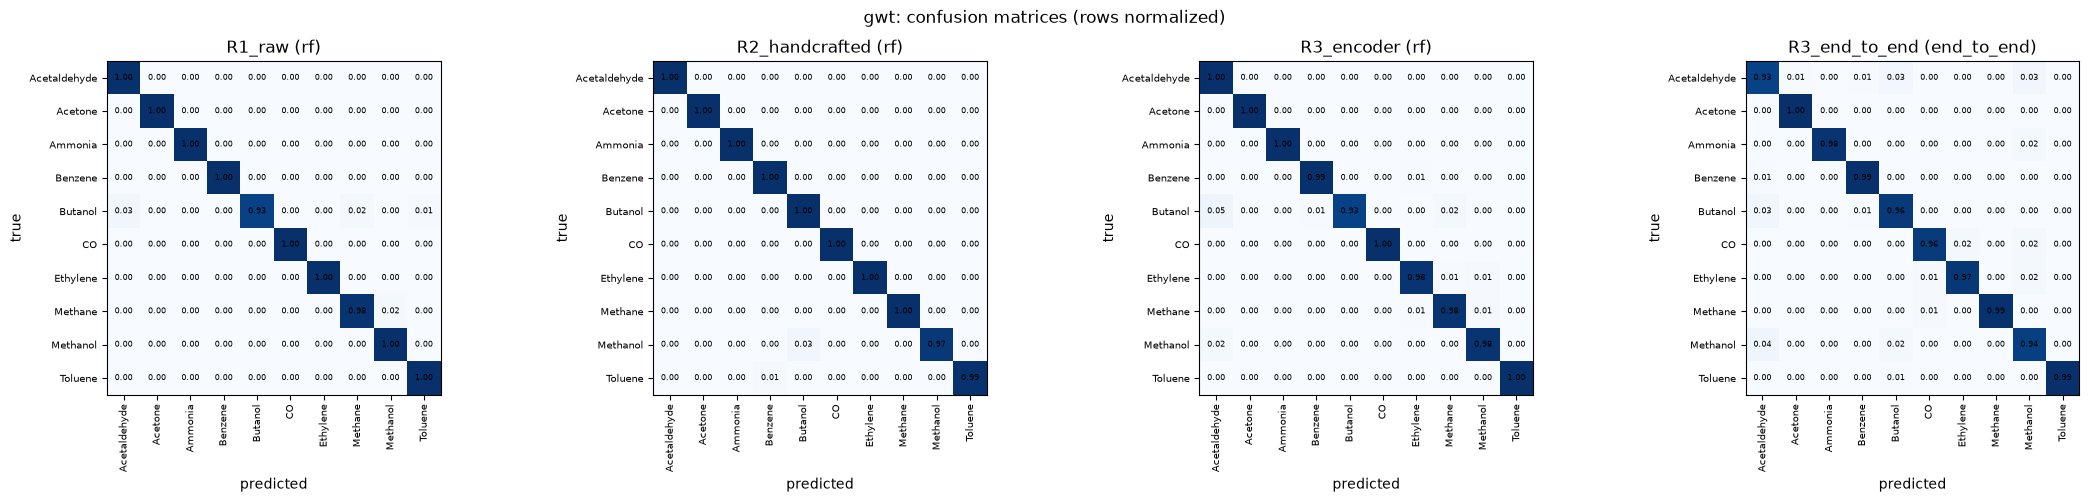

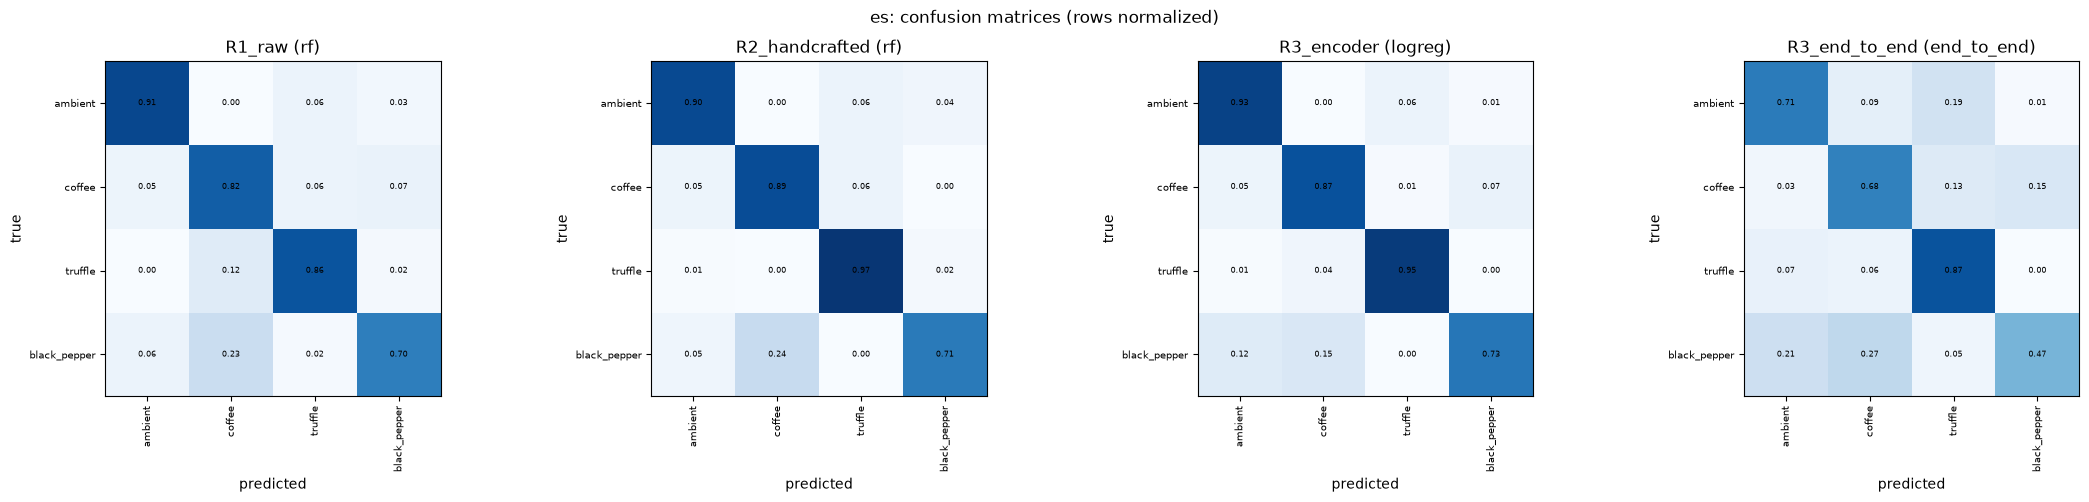

In [5]:
preds = pd.concat([pd.read_csv(RESULTS / f"{n}_preds.csv") for n in MAIN], ignore_index=True)
classes = {d: json.load(open(ROOT / f"data/processed/{f}/info.json"))["classes"]
           for d, f in [("gwt", "gas_wind_tunnel"), ("es", "everyday_scents")]}

for dataset in ["gwt", "es"]:
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    for ax, rep in zip(axes, REPS + ["R3_end_to_end"]):
        if rep == "R3_end_to_end":
            head = "end_to_end"
        else:
            means = scores[(scores["dataset"] == dataset) & (scores["task"] == "multi") & (scores["rep"] == rep)]
            head = means.groupby("head")["macro_f1"].mean().idxmax()
        p = preds[(preds["dataset"] == dataset) & (preds["task"] == "multi") & (preds["rep"] == rep) & (preds["head"] == head)]
        K = len(classes[dataset])
        cm = confusion_matrix(p["y_true"], p["y_pred"], labels=range(K), normalize="true")   # (K, K)
        ax.imshow(cm, vmin=0, vmax=1, cmap="Blues")
        ax.set(xticks=range(K), yticks=range(K), xlabel="predicted", ylabel="true", title=f"{rep} ({head})")
        ax.set_xticklabels(classes[dataset], rotation=90, fontsize=7)
        ax.set_yticklabels(classes[dataset], fontsize=7)
        for a in range(K):
            for c in range(K):
                ax.text(c, a, f"{cm[a, c]:.2f}", ha="center", va="center", fontsize=6)
    fig.suptitle(f"{dataset}: confusion matrices (rows normalized)")
    plt.tight_layout()
    plt.savefig(FIG / f"04a_confusion_{dataset}.png", dpi=150)
    plt.show()

## Colab: save the outputs
Colab deletes everything when the session ends. This zips `results/` and `report/` into `outputs_<notebook>.zip`,
copies it to your Google Drive (`MyDrive/gas-repr-guide/`) and downloads it. On a laptop it does nothing.

In [6]:
if IN_COLAB:
    out_zip = shutil.make_archive(f"/content/outputs_04a_main_tables", "zip", REPO, "results")
    shutil.make_archive(f"/content/report_04a_main_tables", "zip", REPO, "report")
    files_out = [out_zip, f"/content/report_04a_main_tables.zip"]
    print(files_out)
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        out_dir = "/content/drive/MyDrive/gas-repr-guide"
        os.makedirs(out_dir, exist_ok=True)
        for f in files_out:
            shutil.copy(f, out_dir)
        print("copied to", out_dir)
    except Exception as e:
        print("Drive copy failed:", e)
    from google.colab import files
    for f in files_out:
        files.download(f)